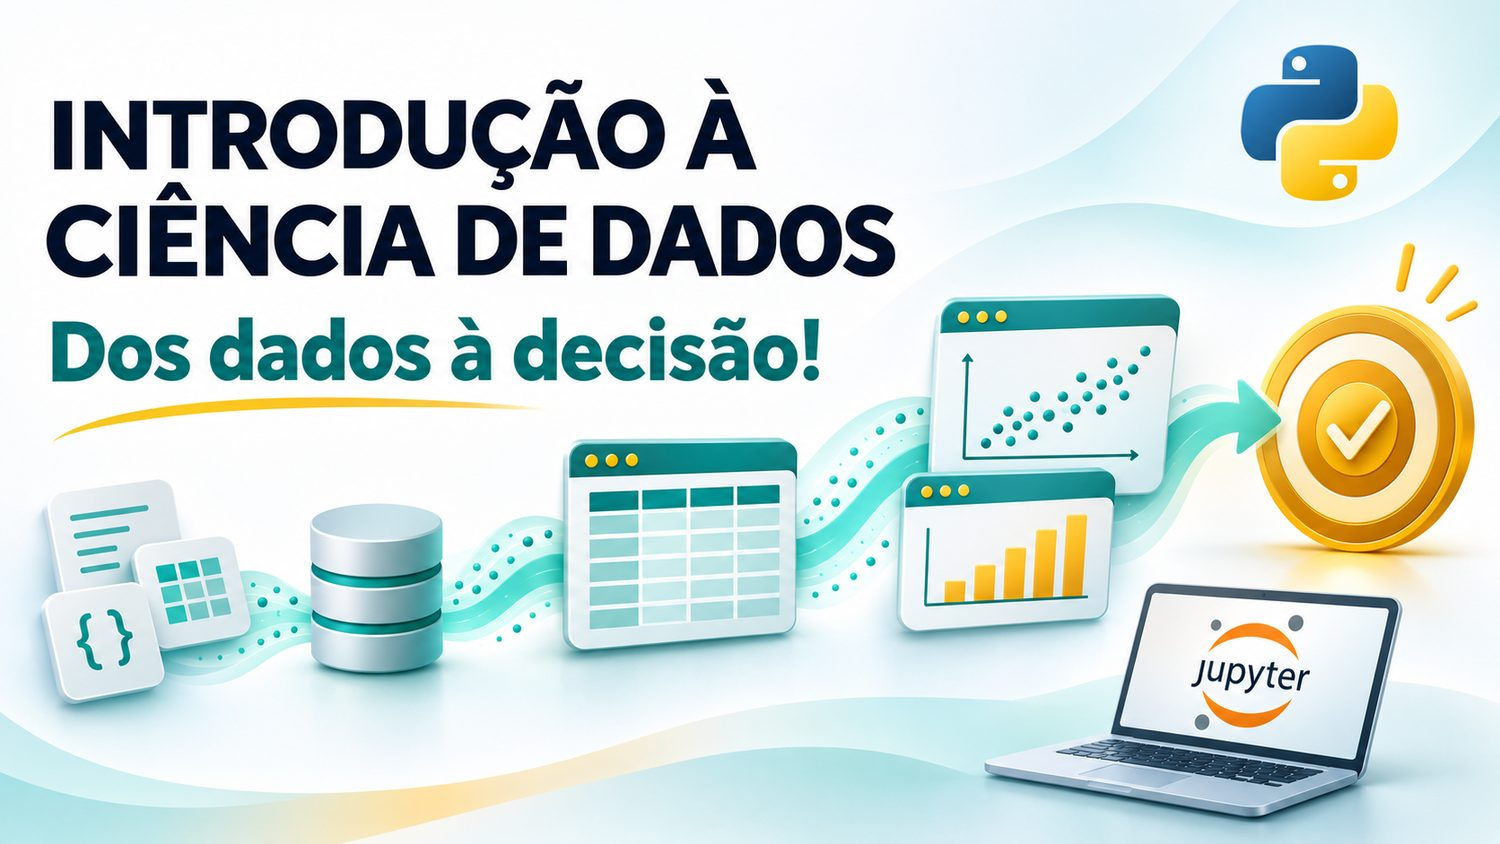

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_4_preparar_os_dados/01_O_que_e_Aprender_com_Dados.ipynb)

# Capítulo 1 – O que é aprender com dados

Até aqui descrevemos e explorámos. Agora começa a preparação para **prever**. Antes de qualquer técnica, este capítulo explica o que quer dizer um programa «aprender», que tipos de aprendizagem existem e o que é, afinal, um modelo.

> **Objetivos:** distinguir um programa escrito à mão de um modelo aprendido; aplicar a definição de aprendizagem de Mitchell (tarefa, experiência, desempenho); usar o vocabulário de atributos, alvo, treino e previsão; distinguir aprendizagem supervisionada (regressão e classificação) de não supervisionada; explicar o que é ajustar um modelo; reconhecer quando a aprendizagem automática não é a ferramenta certa.

**Pré-requisitos:** módulos 1 a 3. A sintaxe do scikit-learn está em [Scikit-Learn: fundamentos](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_2_avancado/N2_03_ScikitLearn_Fundamentos.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## O caso deste módulo: quanto vale um carro usado?

Um stand recebe todas as semanas dezenas de carros usados e tem de decidir a que preço os anuncia. Hoje quem decide é um avaliador experiente. O stand quer um sistema que proponha um preço a partir das características do carro, e tem o histórico de três mil anúncios.

Os dados são sintéticos e as marcas são inventadas.

In [2]:
def gerar_carros(n=3000, semente=17):
    """Gera anúncios de carros usados de um stand fictício (dados sintéticos; as marcas são inventadas)."""
    rng = np.random.default_rng(semente)
    segmentos = {"citadino": (11000, 75), "utilitário": (15000, 100), "familiar": (21000, 130),
                 "SUV": (27000, 150), "monovolume": (23000, 125), "desportivo": (38000, 240)}
    marcas = {"Alba": 1.00, "Boreal": 0.92, "Cimo": 1.08, "Dueto": 0.95, "Estela": 1.30, "Faro": 1.00,
              "Gávea": 0.88, "Hera": 1.45, "Ípsilon": 1.05, "Jade": 0.97, "Kappa": 1.60, "Lume": 0.90}
    frequencia = np.array([18, 16, 14, 12, 9, 9, 7, 5, 4, 3, 2, 1], dtype=float)
    segmento = rng.choice(list(segmentos), n, p=[0.24, 0.28, 0.18, 0.18, 0.08, 0.04])
    marca = rng.choice(list(marcas), n, p=frequencia / frequencia.sum())
    ano = rng.integers(2008, 2026, n)
    idade = 2026 - ano
    km = (idade * 14000 * rng.lognormal(0, 0.35, n) + rng.uniform(500, 6000, n)).round(-2)
    potencia = np.array([segmentos[s][1] for s in segmento]) * rng.normal(1, 0.12, n)
    prob_eletrico = np.clip((ano - 2016) * 0.03, 0, 0.25)
    sorteio = rng.random(n)
    combustivel = np.where(sorteio < prob_eletrico, "elétrico", np.where(sorteio < prob_eletrico + 0.15, "híbrido",
                           np.where(sorteio < prob_eletrico + 0.55, "gasóleo", "gasolina")))
    caixa_velocidades = np.where(rng.random(n) < 0.25 + 0.4 * (combustivel == "elétrico"), "automática", "manual")
    niveis = np.array(["mau", "razoável", "bom", "excelente"])
    estado = niveis[np.clip(rng.normal(2.2 - 0.06 * idade, 0.8, n).round(), 0, 3).astype(int)]
    fator_estado = pd.Series(estado).map({"mau": 0.78, "razoável": 0.92, "bom": 1.0, "excelente": 1.08}).to_numpy()
    ruido = rng.lognormal(0, 0.10, n)                      # o que o preço tem de «caro» ou de «barato» sem explicação
    preco = (np.array([segmentos[s][0] for s in segmento]) * np.array([marcas[m] for m in marca])
             * np.exp(-0.085 * idade) * np.exp(-km / 420000) * fator_estado
             * np.where(caixa_velocidades == "automática", 1.08, 1.0)
             * np.where(combustivel == "elétrico", 1.25, np.where(combustivel == "híbrido", 1.12, 1.0))
             * (potencia / np.array([segmentos[s][1] for s in segmento])) ** 0.4 * ruido)
    carros = pd.DataFrame({
        "marca": marca, "segmento": segmento, "ano": ano, "km": km, "potencia_cv": potencia.round(),
        "combustivel": combustivel, "caixa": caixa_velocidades, "estado": estado,
        "cor": rng.choice(["branco", "cinzento", "preto", "azul", "vermelho"], n), "preco": preco.round(-1)})
    nivel = pd.Series(estado).map({"mau": 0, "razoável": 1, "bom": 2, "excelente": 3}).to_numpy()
    z = (-0.2 + 0.75 * (nivel - 1.5) - 0.07 * idade + 0.7 * np.isin(segmento, ["SUV", "utilitário"])
         + 0.5 * (caixa_velocidades == "automática") - 5 * np.log(ruido))
    carros["vendido_30_dias"] = rng.random(n) < 1 / (1 + np.exp(-z))
    # Valores em falta: quem tem muitos quilómetros «esquece-se» mais vezes de os indicar
    carros.loc[rng.random(n) < 0.03 + 0.25 * (km > np.quantile(km, 0.8)), "km"] = np.nan
    carros.loc[rng.random(n) < 0.06, "potencia_cv"] = np.nan
    carros.loc[rng.random(n) < 0.05, "estado"] = np.nan
    return carros


carros = gerar_carros()
carros.head()

,marca,segmento,ano,km,potencia_cv,combustivel,caixa,estado,cor,preco,vendido_30_dias
0,Boreal,SUV,2019,127500.0,199.0,híbrido,automática,razoável,cinzento,15250.0,False
1,Gávea,citadino,2012,171200.0,67.0,gasolina,manual,bom,azul,1630.0,False
2,Gávea,familiar,2018,123900.0,116.0,gasóleo,automática,bom,preto,6670.0,True
3,Cimo,utilitário,2009,239000.0,98.0,gasolina,manual,bom,cinzento,2350.0,False
4,Boreal,citadino,2016,122600.0,51.0,gasóleo,manual,bom,branco,3080.0,False


| Coluna | Significado | Tipo |
| --- | --- | --- |
| `marca` | Marca do carro (12 marcas) | nominal |
| `segmento` | Tipo de carro (citadino, utilitário, familiar, SUV, monovolume, desportivo) | nominal |
| `ano` | Ano de matrícula | discreta |
| `km` | Quilómetros percorridos | contínua |
| `potencia_cv` | Potência, em cavalos | contínua |
| `combustivel` | Gasolina, gasóleo, híbrido ou elétrico | nominal |
| `caixa` | Manual ou automática | nominal |
| `estado` | Mau, razoável, bom ou excelente | ordinal |
| `cor` | Cor da carroçaria | nominal |
| `preco` | Preço do anúncio, em euros | contínua |
| `vendido_30_dias` | Se o carro foi vendido em 30 dias | booleana |

## Escrever regras ou aprendê-las

Há duas formas de pôr um computador a propor preços.

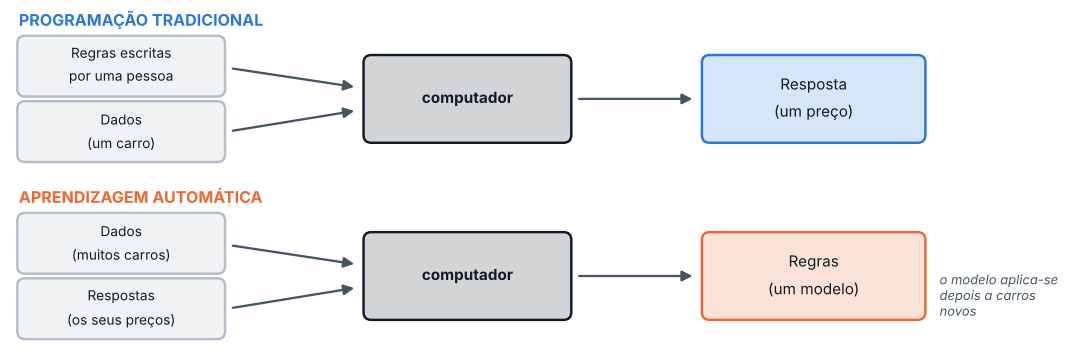

In [3]:
fig, ax = tela(13, 4.4, (12, 4))
for y, titulo, entradas, saida, cor in [(2.5, "PROGRAMAÇÃO TRADICIONAL", ["Regras escritas\npor uma pessoa", "Dados\n(um carro)"], "Resposta\n(um preço)", AZUL),
                                        (0.2, "APRENDIZAGEM AUTOMÁTICA", ["Dados\n(muitos carros)", "Respostas\n(os seus preços)"], "Regras\n(um modelo)", LARANJA)]:
    ax.text(0.1, y + 1.75, titulo, fontweight="bold", color=cor, fontsize=10.5)
    caixa(ax, 0.1, y + 0.85, 2.6, 0.75, entradas[0], CINZA, 9)
    caixa(ax, 0.1, y, 2.6, 0.75, entradas[1], CINZA, 9)
    seta(ax, (2.78, y + 1.2), (4.4, y + 0.95))
    seta(ax, (2.78, y + 0.38), (4.4, y + 0.65))
    caixa(ax, 4.5, y + 0.25, 2.6, 1.1, "computador", TINTA, 10, True)
    seta(ax, (7.18, y + 0.8), (8.7, y + 0.8))
    caixa(ax, 8.8, y + 0.25, 2.8, 1.1, saida, cor, 10)
ax.text(11.8, 0.75, "o modelo aplica-se\ndepois a carros\nnovos", fontsize=8.5, color="#465463", style="italic", va="center")
plt.show()

Na programação tradicional, uma pessoa escreve as regras:

In [4]:
def preco_por_regras(carro):
    """Uma avaliação escrita à mão, como a faria um avaliador apressado."""
    preco = {"citadino": 11000, "utilitário": 15000, "familiar": 21000, "SUV": 27000, "monovolume": 23000, "desportivo": 38000}[carro["segmento"]]
    preco *= 0.92 ** (2026 - carro["ano"])             # perde 8% por ano
    if carro["estado"] == "mau":
        preco *= 0.8
    return preco


carros["preco_regras"] = carros.apply(preco_por_regras, axis=1)
erro_regras = (carros["preco_regras"] - carros["preco"]).abs().mean()
print(f"Erro absoluto médio das regras escritas à mão: {erro_regras:.0f} €")

Erro absoluto médio das regras escritas à mão: 2329 €


As regras funcionam razoavelmente, mas alguém teve de as inventar, e ficam por rever sempre que o mercado muda. Faltam-lhes os quilómetros, a marca, o combustível…

Na aprendizagem automática, mostram-se ao computador muitos carros **com o preço a que foram anunciados**, e ele procura sozinho uma regra que ligue as características ao preço. Essa regra é o **modelo**.

## A definição de Mitchell

A definição mais citada é de Tom Mitchell (1997). Em palavras simples:

> Um programa **aprende** com a experiência **E**, em relação a uma tarefa **T** e a uma medida de desempenho **P**, se o seu desempenho em T, medido por P, melhora com a experiência E.

A definição obriga a responder a três perguntas antes de começar.

| | Pergunta | No caso do stand | Deteção de correio indesejado | Diagnóstico por imagem |
| --- | --- | --- | --- | --- |
| **T** – tarefa | O que tem de fazer? | Propor o preço de um carro | Classificar uma mensagem | Assinalar radiografias com lesão |
| **E** – experiência | Com o que aprende? | Anúncios anteriores, com o preço | Mensagens já classificadas | Radiografias com o diagnóstico |
| **P** – desempenho | Como se mede se está melhor? | Erro médio, em euros | Proporção de mensagens bem classificadas | Lesões detetadas e falsos alarmes |

Se uma das três não tiver resposta clara, o projeto não está pronto para modelar. A medida **P** é a que mais se esquece, e é a que liga o modelo à decisão (módulo 1, capítulo 3).

Vamos ver a definição a funcionar: o mesmo modelo, treinado com cada vez mais anúncios, avaliado sempre nos mesmos 600 carros que nunca viu.

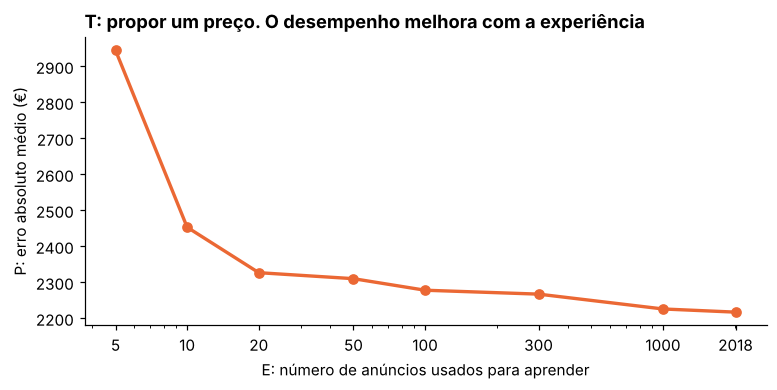

In [5]:
from sklearn.linear_model import LinearRegression

completos = carros.dropna(subset=["km", "potencia_cv"]).assign(idade=lambda t: 2026 - t["ano"])
teste = completos.sample(600, random_state=0)
resto = completos.drop(teste.index)
atributos = ["idade", "km", "potencia_cv"]

tamanhos = [5, 10, 20, 50, 100, 300, 1000, len(resto)]
erros = []
for n in tamanhos:
    repeticoes = []
    for semente in range(30):                                 # várias amostras de cada tamanho
        treino = resto.sample(n, random_state=semente)
        modelo = LinearRegression().fit(treino[atributos], treino["preco"])
        repeticoes.append((modelo.predict(teste[atributos]) - teste["preco"]).abs().mean())
    erros.append(np.median(repeticoes))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(tamanhos, erros, color=LARANJA, lw=2.2, marker="o")
ax.set_xscale("log")
ax.set_xticks(tamanhos, [str(n) for n in tamanhos])
ax.set_xlabel("E: número de anúncios usados para aprender")
ax.set_ylabel("P: erro absoluto médio (€)")
ax.set_title("T: propor um preço. O desempenho melhora com a experiência")
plt.show()

O erro desce depressa nos primeiros exemplos e depois estabiliza. A partir de certo ponto, mais dados do mesmo tipo já não ajudam: o que falta ao modelo é outra informação (a marca, o segmento, o estado) ou outra forma.

## O vocabulário

| Termo | Outros nomes | Significado | No caso do stand |
| --- | --- | --- | --- |
| **Observação** | exemplo, instância, linha | Um caso | Um anúncio |
| **Atributos** | variáveis de entrada, *features*, **X** | O que se conhece de cada caso | Idade, km, potência… |
| **Alvo** | variável de saída, rótulo, *target*, **y** | O que se quer prever | O preço |
| **Modelo** | | Uma regra que transforma atributos numa previsão | Uma fórmula, uma árvore… |
| **Treinar** | ajustar, *fit* | Escolher a regra a partir dos exemplos | `modelo.fit(X, y)` |
| **Prever** | *predict* | Aplicar a regra a casos novos | `modelo.predict(X_novo)` |

In [6]:
X = completos[atributos]                 # atributos: uma tabela, uma linha por carro
y = completos["preco"]                   # alvo: uma coluna

print("X:", X.shape, "| y:", y.shape)
modelo = LinearRegression().fit(X, y)                                            # treinar
carro_novo = pd.DataFrame({"idade": [6], "km": [85000], "potencia_cv": [110]})
print(f"Preço proposto para um carro com 6 anos, 85 000 km e 110 cv: {modelo.predict(carro_novo)[0]:.0f} €")    # prever

X: (2618, 3) | y: (2618,)
Preço proposto para um carro com 6 anos, 85 000 km e 110 cv: 10837 €


Todos os modelos do scikit-learn usam estes dois verbos, `fit` e `predict`. Mudar de modelo é mudar uma linha.

## Três famílias de aprendizagem

### Supervisionada: há um alvo

Cada exemplo de treino tem a resposta certa. Conforme o tipo do alvo (módulo 2, capítulo 2), a tarefa tem dois nomes.

| Tarefa | O alvo é… | Exemplos |
| --- | --- | --- |
| **Regressão** | uma quantidade | Preço de um carro, consumo de amanhã, tempo de espera |
| **Classificação** | uma categoria | Vende em 30 dias ou não, mensagem indesejada ou não, tipo de avaria |

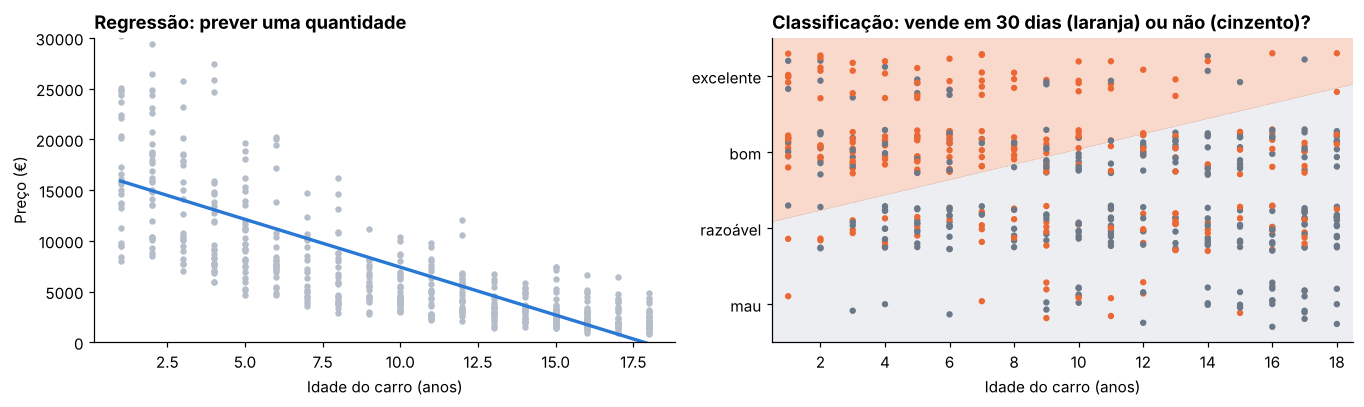

In [7]:
from sklearn.linear_model import LogisticRegression

amostra = completos.sample(500, random_state=3)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.8))

ax1.scatter(amostra["idade"], amostra["preco"], s=10, color=CINZA)
anos = np.arange(1, 19)
reta = LinearRegression().fit(completos[["idade"]], completos["preco"])
ax1.plot(anos, reta.predict(pd.DataFrame({"idade": anos})), color=AZUL, lw=2.2)
ax1.set_ylim(0, 30000)
ax1.set_xlabel("Idade do carro (anos)")
ax1.set_ylabel("Preço (€)")
ax1.set_title("Regressão: prever uma quantidade")

com_estado = completos.dropna(subset=["estado"]).assign(nivel=lambda t: t["estado"].map({"mau": 0, "razoável": 1, "bom": 2, "excelente": 3}))
classificador = LogisticRegression().fit(com_estado[["idade", "nivel"]], com_estado["vendido_30_dias"])
grelha_idade, grelha_nivel = np.meshgrid(np.linspace(0.5, 18.5, 100), np.linspace(-0.5, 3.5, 100))
probabilidade = classificador.predict_proba(pd.DataFrame({"idade": grelha_idade.ravel(), "nivel": grelha_nivel.ravel()}))[:, 1]
ax2.contourf(grelha_idade, grelha_nivel, probabilidade.reshape(grelha_idade.shape), levels=[0, 0.5, 1], colors=[CINZA + "40", LARANJA + "40"])
pontos = com_estado.sample(500, random_state=3)
tremor = np.random.default_rng(0).uniform(-0.3, 0.3, len(pontos))
ax2.scatter(pontos["idade"], pontos["nivel"] + tremor, s=10, color=np.where(pontos["vendido_30_dias"], LARANJA, "#6b7887"))
ax2.set_yticks(range(4), ["mau", "razoável", "bom", "excelente"])
ax2.set_xlabel("Idade do carro (anos)")
ax2.set_title("Classificação: vende em 30 dias (laranja) ou não (cinzento)?")
plt.tight_layout()
plt.show()

À esquerda, o modelo é uma **reta**: para cada idade propõe um preço. À direita, o modelo é uma **fronteira**: de um lado prevê «vende», do outro «não vende». Nos dois casos há pontos longe da reta e do lado errado da fronteira. Um modelo não acerta sempre; acerta melhor do que quem não tem modelo.

### Não supervisionada: não há alvo

Só há atributos. O objetivo é encontrar estrutura: grupos de casos parecidos, ou uma forma mais simples de descrever os dados. É o tema do módulo 7.

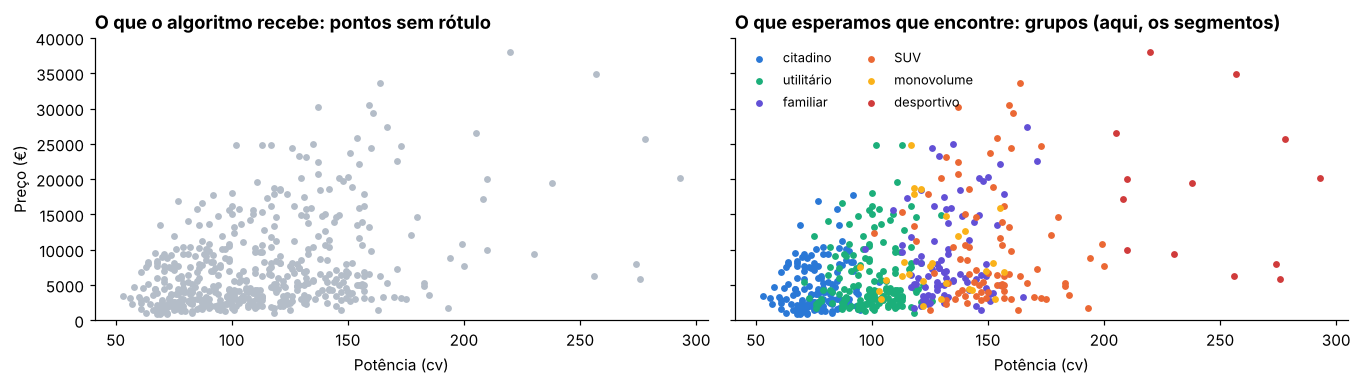

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.6), sharey=True)
ax1.scatter(amostra["potencia_cv"], amostra["preco"], s=12, color=CINZA)
ax1.set_title("O que o algoritmo recebe: pontos sem rótulo")
for segmento, cor in zip(["citadino", "utilitário", "familiar", "SUV", "monovolume", "desportivo"], [AZUL, VERDE, VIOLETA, LARANJA, AVISO, MAU]):
    parte = amostra[amostra["segmento"] == segmento]
    ax2.scatter(parte["potencia_cv"], parte["preco"], s=12, color=cor, label=segmento)
ax2.legend(frameon=False, fontsize=8.5, ncol=2)
ax2.set_title("O que esperamos que encontre: grupos (aqui, os segmentos)")
for ax in (ax1, ax2):
    ax.set_xlabel("Potência (cv)")
    ax.set_ylim(0, 40000)
ax1.set_ylabel("Preço (€)")
plt.tight_layout()
plt.show()

### Por reforço: aprender com as consequências

Há uma terceira família, em que um agente toma decisões em sequência e aprende com as recompensas que recebe (jogos, robótica, afinação de preços em tempo real). Fica fora deste tutorial.

| | Supervisionada | Não supervisionada |
| --- | --- | --- |
| **Os dados têm** | atributos e alvo | só atributos |
| **Objetivo** | prever o alvo em casos novos | encontrar estrutura |
| **Como se avalia** | comparando com as respostas certas | não há resposta certa: avalia-se pela utilidade |
| **Módulo** | 5 | 6 |

## O que é um modelo, por dentro

Um modelo é uma **família de regras** com alguns números por escolher, os **parâmetros**. Treinar é procurar os parâmetros que dão o menor erro nos exemplos.

O modelo mais simples é uma reta: `preço = a + b × idade`. Tem dois parâmetros. Vamos fixar `a` e experimentar vários valores de `b`.

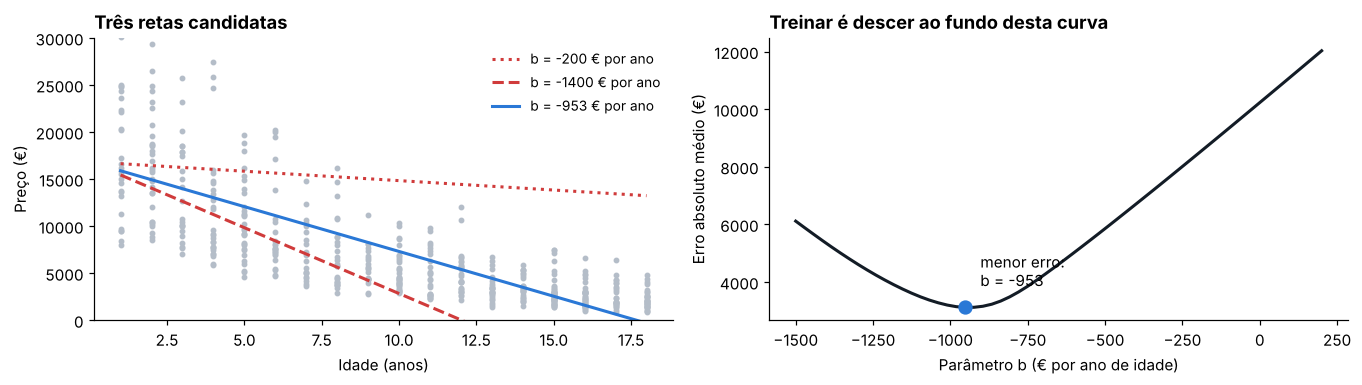

In [9]:
idade, preco = completos["idade"].to_numpy(), completos["preco"].to_numpy()
a = reta.intercept_                                   # o melhor valor de a, já calculado acima
declives = np.linspace(-1500, 200, 60)
erros = [np.mean(np.abs(a + b * idade - preco)) for b in declives]
melhor = declives[int(np.argmin(erros))]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.6))
ax1.scatter(amostra["idade"], amostra["preco"], s=8, color=CINZA)
for b, cor, estilo in [(-200, MAU, ":"), (-1400, MAU, "--"), (melhor, AZUL, "-")]:
    ax1.plot(anos, a + b * anos, color=cor, lw=2, ls=estilo, label=f"b = {b:.0f} € por ano")
ax1.set_ylim(0, 30000)
ax1.set_xlabel("Idade (anos)")
ax1.set_ylabel("Preço (€)")
ax1.legend(frameon=False, fontsize=9)
ax1.set_title("Três retas candidatas")
ax2.plot(declives, erros, color=TINTA, lw=2)
ax2.scatter([melhor], [min(erros)], color=AZUL, s=70, zorder=3)
ax2.annotate(f"menor erro:\nb = {melhor:.0f}", (melhor, min(erros)), textcoords="offset points", xytext=(10, 14))
ax2.set_xlabel("Parâmetro b (€ por ano de idade)")
ax2.set_ylabel("Erro absoluto médio (€)")
ax2.set_title("Treinar é descer ao fundo desta curva")
plt.tight_layout()
plt.show()

Cada valor de `b` dá uma reta e um erro. O treino procura o ponto mais baixo da curva da direita. Com mais parâmetros, a curva passa a ser uma superfície com muitas dimensões, mas a ideia é a mesma.

Modelos diferentes são famílias de regras diferentes: retas (regressão linear), vizinhos parecidos (KNN), perguntas sucessivas (árvores de decisão). Os módulos 5 e 6 tratam de cada um.

## O objetivo é acertar no que ainda não se viu

Um modelo treinado só interessa pelo que faz com carros **novos**. Ora, há uma forma trivial de ter erro zero nos exemplos de treino: decorá-los.

In [10]:
memoria = dict(zip(map(tuple, X.round().to_numpy()), y))        # um «modelo» que decora todos os exemplos


def prever_de_cor(linha):
    return memoria.get(tuple(linha.round()), np.nan)


conhecido = X.iloc[[0]]
print("Carro que está nos dados:", prever_de_cor(conhecido.to_numpy()[0]), "€ (certo:", y.iloc[0], "€)")
print("Carro novo:", prever_de_cor(carro_novo.to_numpy()[0]))

Carro que está nos dados: 15250.0 € (certo: 15250.0 €)
Carro novo: nan


O «modelo» que decora acerta em cheio nos carros que já viu e não tem nada a dizer sobre um carro novo. Aprender é **generalizar**: encontrar uma regra que funcione para lá dos exemplos.

Isto tem uma consequência prática imediata: o desempenho de um modelo nunca se mede nos dados com que foi treinado. É o tema do próximo capítulo.

## Quando não é preciso aprendizagem automática

Um modelo aprendido tem custos: precisa de dados, de manutenção e de alguém que perceba quando deixou de funcionar. Não compensa quando:

- **uma regra simples chega.** Se o preço fosse sempre «valor de tabela menos 8% por ano», bastava a fórmula;
- **não há alvo registado.** Sem exemplos com a resposta certa, não há aprendizagem supervisionada;
- **há poucos exemplos**, ou os exemplos não se parecem com os casos futuros;
- **a decisão exige uma justificação** que o modelo não consegue dar;
- **o erro custa mais do que o benefício**, e não há uma pessoa a rever as previsões.

A pergunta útil não é «conseguimos treinar um modelo?», porque quase sempre se consegue. É «o modelo faz melhor do que aquilo que já temos, o suficiente para justificar o trabalho?». Para isso é preciso uma linha de base.

## Exercícios

### `Exercício 1` – T, E e P

Indica a tarefa, a experiência e a medida de desempenho de cada sistema:

1. Um tradutor automático.
2. Um sistema que recomenda filmes.
3. Um programa que prevê a procura de pão em cada loja (módulo 2).

<details>
<summary><b>Ver uma solução possível</b></summary>

1. T: traduzir uma frase; E: milhões de frases com a tradução feita por pessoas; P: semelhança com traduções de referência, ou avaliação por leitores.
2. T: ordenar filmes para um utilizador; E: o que cada utilizador viu e avaliou; P: proporção de recomendações que foram vistas ou bem avaliadas.
3. T: prever os pães vendidos por loja e por dia; E: vendas anteriores, com dia da semana, meteorologia e eventos; P: erro absoluto médio em pães, ou o custo das sobras e das ruturas.

</details>

### `Exercício 2` – Regressão, classificação ou não supervisionada?

1. Estimar o tempo de entrega de uma encomenda.
2. Decidir se uma transação é fraudulenta.
3. Agrupar clientes com hábitos de compra parecidos.
4. Prever quantas estrelas (de 1 a 5) um cliente dará a um hotel.
5. Identificar a espécie de uma planta numa fotografia.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Regressão.
2. Classificação.
3. Não supervisionada.
4. Pode ser tratada como regressão ou como classificação. O alvo é **ordinal**: a classificação ignora a ordem, a regressão trata as distâncias como iguais. Nenhuma das duas é perfeita.
5. Classificação.

</details>

### `Exercício 3` – Outro atributo, outra reta

Ajusta uma regressão linear do preço só com os quilómetros, e outra só com a potência. Qual dos três atributos (idade, km, potência) dá o menor erro quando usado sozinho?

In [11]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for coluna in ["idade", "km", "potencia_cv"]:
    m = LinearRegression().fit(completos[[coluna]], completos["preco"])
    erro = (m.predict(completos[[coluna]]) - completos["preco"]).abs().mean()
    print(f"{coluna:<12} erro: {erro:.0f} €")
```

A idade e os quilómetros dão erros parecidos (medem quase a mesma coisa: o uso do carro). A potência, sozinha, dá um erro maior. Repara que estes erros foram medidos nos mesmos carros com que o modelo foi treinado, o que os torna otimistas. O capítulo seguinte corrige isso.

</details>

### `Exercício 4` – Melhorar as regras à mão

Altera a função `preco_por_regras` para ter em conta os quilómetros (quando existirem). Consegues um erro mais baixo do que o do modelo linear com três atributos?

In [12]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def regras_melhoradas(carro):
    preco = preco_por_regras(carro)
    if pd.notna(carro["km"]):
        esperado = 14000 * (2026 - carro["ano"])
        preco *= 1 - 0.15 * (carro["km"] - esperado) / 100000      # mais km do que o habitual: desconto
    return preco


erro = (completos.apply(regras_melhoradas, axis=1) - completos["preco"]).abs().mean()
print(f"Regras melhoradas: {erro:.0f} €")
```

Regras bem pensadas, com conhecimento do domínio (o segmento!), ficam muito perto de um modelo linear que só vê três números, e podem batê-lo. Não é um argumento contra os modelos: é um argumento para lhes dar os atributos certos, e para usar as regras à mão como linha de base.

</details>

## Verifica o que aprendeste

- [ ] Sei explicar a diferença entre escrever regras e aprendê-las.
- [ ] Sei enunciar a definição de Mitchell e identificar T, E e P num problema.
- [ ] Sei o que são atributos, alvo, treinar e prever.
- [ ] Sei distinguir regressão de classificação, e aprendizagem supervisionada de não supervisionada.
- [ ] Sei explicar o que são os parâmetros de um modelo e o que é ajustá-los.
- [ ] Sei porque decorar os exemplos não é aprender.
- [ ] Sei dar exemplos de situações em que a aprendizagem automática não compensa.

## Leitura recomendada

- https://scikit-learn.org/stable/getting_started.html
- https://en.wikipedia.org/wiki/Machine_learning
- https://en.wikipedia.org/wiki/Supervised_learning